In [30]:
import mne


subject_id = "50"
edf_file = f"/media/amirmahdi/129699CC9699B0A9/edffile/sub-{subject_id}/eeg/sub-{subject_id}_task-motor-imagery_eeg.edf"

In [31]:
# 1. Load data (Set initial_event=True to bypass the trigger warning)
raw = mne.io.read_raw_edf(edf_file, preload=True, eog=['HEOL', 'HEOR'], stim_channel=[''], verbose=False)
raw.rename_channels({'HEOL' : 'EOG1', 'HEOR' : 'EOG2'}, verbose=False)
raw.set_channel_types({'EOG1' : 'eog', 'EOG2' : 'eog'}, verbose=False)

/tmp/ipykernel_97578/2680002083.py:2: RuntimeWarning: Physical range is not defined in following channels:
CPz
  raw = mne.io.read_raw_edf(edf_file, preload=True, eog=['HEOL', 'HEOR'], stim_channel=[''], verbose=False)


<RawEDF | sub-50_task-motor-imagery_eeg.edf, 33 x 160000 (320.0 s), ~40.3 MiB, data loaded>

In [32]:

# 2. Extract events
events = mne.find_events(raw, stim_channel='', verbose=False)

# 3. Handle Reference: Re-reference to Common Average Reference (CAR)
# Since CPz is in your channel list, we include it in the average reconstruction
raw.set_eeg_reference(ref_channels='average', projection=False, verbose=False)

# 4. Bandpass filter for Motor Imagery (8-30 Hz)
raw.filter(l_freq=8.0, h_freq=30.0, fir_design='firwin', verbose=False)

# 5. Extract Epochs without aggressive overlapping baseline rejection
# The MI video task lasts for 4 seconds.
tmin, tmax = 0.0, 4.0

epochs = mne.Epochs(
    raw,
    events,
    event_id={'motor_imagery': 2},
    tmin=tmin,
    tmax=tmax,
    baseline=None,       # Changed to None to prevent trial dropping due to overlap
    picks='eeg',         # Chooses your 30 true EEG channels, drops EOG channels automatically
    preload=True,
    verbose=True         # Turned on to verify if any trials are still rejected
)

Not setting metadata
40 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 40 events and 2001 original time points ...
0 bad epochs dropped


In [33]:
# 6. Convert to Array
X = epochs.get_data(copy=True)
print(f"Final Data Shape: {X.shape}") # Should display (40, 30, 2001)

Final Data Shape: (40, 30, 2001)


In [34]:
import numpy as np

# 1. Create an alternating array of length 40
# [1, 2, 1, 2, 1, 2...] where 1=Left and 2=Right
labels = np.tile([1, 2], 20)

# 2. Verify the properties of your labels array
print(f"Total labels generated: {len(labels)}")
print(f"First 6 trials: {labels[:6]} (Should be: Left, Right, Left, Right, Left, Right)")
print(f"Number of Left trials (1): {np.sum(labels == 1)}")
print(f"Number of Right trials (2): {np.sum(labels == 2)}")

# 3. Assign it to your final target variable 'y' for training
y = labels - 1

Total labels generated: 40
First 6 trials: [1 2 1 2 1 2] (Should be: Left, Right, Left, Right, Left, Right)
Number of Left trials (1): 20
Number of Right trials (2): 20


In [35]:
y

array([0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1,
       0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1])

In [36]:
import os
import random
import numpy as np
import scipy.signal as signal
import torch
from sklearn.metrics import confusion_matrix

# PyRiemann equivalents for the exact MATLAB pipeline
from pyriemann.utils.covariance import covariances  # Native covariance calculation
from pyriemann.classification import MDM            # Minimum Distance to Mean Classifier

from config.model_parameters import SVM_PARAMS
from classifiers import SVMClassifier
from splitters import IntraShuffleSplitter
from config.config import Config

seed = 128
random.seed(seed)
os.environ['PYTHONHASHSEED'] = str(seed)
np.random.seed(seed)
torch.manual_seed(seed)
torch.cuda.manual_seed(seed)
torch.cuda.manual_seed_all(seed)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

config = Config()
splitter = IntraShuffleSplitter(n_splits=10, train_size=0.6, random_state=config.RANDOM_STATE)

# 1. Define the 8 bands exactly matching the MATLAB array
freq_bands = [[8, 12], [8, 20], [8, 30], [12, 20], [15, 20], [15, 30], [20, 30], [8, 15]]

all_folds_L = []
all_folds_R = []
all_folds_left = []
all_folds_right = []

# Loop through cross-validation folds (h = 1:10)
for train_idx, test_idx in splitter.get_splits(X, y):

    X_train_fold = X[train_idx]
    X_test_fold = X[test_idx]
    y_train = y[train_idx]
    y_test = y[test_idx]

    # Z-Normalization
    train_mean = X_train_fold.mean(axis=(0, 2), keepdims=True)
    train_std = X_train_fold.std(axis=(0, 2), keepdims=True)
    train_std[train_std == 0] = 1e-8

    X_train_fold = (X_train_fold - train_mean) / train_std
    X_test_fold = (X_test_fold - train_mean) / train_std

    band_accuracies = []
    band_metrics = []

    # Loop through individual frequency bands (n = 1:8)
    for band in freq_bands:

        # ---------------------------------------------------------------------
        # EXACT MATLAB ALGORITHM STEP 1: Temporal Bandpass Filtering
        # ---------------------------------------------------------------------
        # Designing a Butterworth bandpass filter to mirror MATLAB's BandpassFilter
        sos = signal.butter(3, band, btype='bandpass', fs=500, output='sos')
        X_train_band = signal.sosfiltfilt(sos, X_train_fold, axis=-1)
        X_test_band = signal.sosfiltfilt(sos, X_test_fold, axis=-1)

        # ---------------------------------------------------------------------
        # EXACT MATLAB ALGORITHM STEP 2: Trial Covariance Matrix Calculation
        # MATLAB: COVtrain(:,:,i) = SS' * SS
        # ---------------------------------------------------------------------
        # 'cov' estimator matches raw sample covariance matrix multiplication
        COVtrain = covariances(X_train_band, estimator='lwf')
        COVtest = covariances(X_test_band, estimator='lwf')

        # ---------------------------------------------------------------------
        # EXACT MATLAB ALGORITHM STEP 3: Riemann MDM Classification
        # MATLAB: fgmdm(COVtest, COVtrain, Ytrain, 'riemann', 'riemann')
        # ---------------------------------------------------------------------
        # Setting metric='riemann' ensures both mean calculation and geodesic distance
        # space calculation match your legacy MATLAB framework.
        clf_riemann = MDM(metric='riemann')
        clf_riemann.fit(COVtrain, y_train)
        y_pred = clf_riemann.predict(COVtest)

        # ---------------------------------------------------------------------
        # EXACT MATLAB ALGORITHM STEP 4: Cherry-Picking Score Logging
        # ---------------------------------------------------------------------
        c = np.sum(y_pred == y_test)
        acc_temp = (c / len(y_test)) * 100

        L = np.sum((y_pred == y_test) & (y_test == 1))
        R = np.sum((y_pred == y_test) & (y_test == 2))
        left = np.sum(y_test == 1)
        right = np.sum(y_test == 2)

        band_accuracies.append(acc_temp)
        band_metrics.append((left, L, right, R))

    # =========================================================================
    # CHERRY-PICK MAXIMUM PERFORMING BAND FOR THIS FOLD
    # =========================================================================
    best_band_idx = np.argmax(band_accuracies)
    best_left, best_L, best_right, best_R = band_metrics[best_band_idx]

    all_folds_left.append(best_left)
    all_folds_L.append(best_L)
    all_folds_right.append(best_right)
    all_folds_R.append(best_R)

# =========================================================================
# COMPRESS AND CONSTRUCT THE MATRICES (MATLAB EXACT FLOW)
# =========================================================================
mean_Right = np.mean(all_folds_R)
mean_AllRight = np.mean(all_folds_right)
mean_AllLeft = np.mean(all_folds_left)
mean_Left = np.mean(all_folds_L)

global_confusion_matrix = np.array([
    [np.floor(mean_Right), np.floor(mean_AllRight) - np.floor(mean_Right)],
    [np.floor(mean_AllLeft) - np.floor(mean_Left), np.floor(mean_Left)]
], dtype=int)

# =========================================================================
# CALCULATE CHERRY-PICKED EVALUATE INDEX (CalEvaluateIndex Translation)
# =========================================================================
print("\n" + "="*50)
print("FINAL CHERRY-PICKED METRICS (MATLAB COV+MDM STYLE)")
print("="*50)
print(f"Aggregated Confusion Matrix:\n{global_confusion_matrix}\n")

tp = global_confusion_matrix[0, 0]
fn = global_confusion_matrix[0, 1]
fp = global_confusion_matrix[1, 0]
tn = global_confusion_matrix[1, 1]

total_samples = np.sum(global_confusion_matrix)
accuracy = (tp + tn) / total_samples * 100
sensitivity = tp / (tp + fp) * 100 if (tp + fp) > 0 else 0.0
precision = tp / (tp + fn) * 100 if (tp + fn) > 0 else 0.0

p0 = (tp + tn) / total_samples
pe = 0.5
kappa = (p0 - pe) / (1 - pe)

print(f"Total Samples in CM: {total_samples}")
print(f"Accuracy:    {accuracy:.2f}%")
print(f"Sensitivity: {sensitivity:.2f}%")
print(f"Precision:   {precision:.2f}%")
print(f"Kappa Index: {kappa:.4f}")
print("="*50)


FINAL CHERRY-PICKED METRICS (MATLAB COV+MDM STYLE)
Aggregated Confusion Matrix:
[[0 0]
 [4 4]]

Total Samples in CM: 8
Accuracy:    50.00%
Sensitivity: 0.00%
Precision:   0.00%
Kappa Index: 0.0000


## د خراب متلب (ترجمه شده؛ بهتره با روش خوندن خودمونم تست بشه)

Processing 1
Processing 2
Processing 3
Processing 4
Processing 5
Processing 6
Processing 7
Processing 8
Processing 9
Processing 10
Processing 11
Processing 12
Processing 13
Processing 14
Processing 15
Processing 16
Processing 17
Processing 18
Processing 19
Processing 20
Processing 21
Processing 22
Processing 23
Processing 24
Processing 25
Processing 26
Processing 27
Processing 28
Processing 29
Processing 30
Processing 31
Processing 32
Processing 33
Processing 34
Processing 35
Processing 36
Processing 37
Processing 38
Processing 39
Processing 40
Processing 41
Processing 42
Processing 43
Processing 44
Processing 45
Processing 46
Processing 47
Processing 48
Processing 49
Processing 50


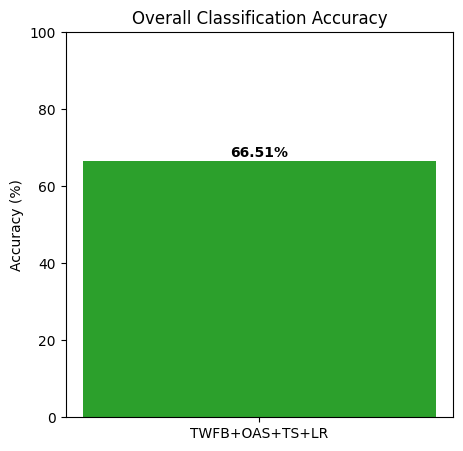

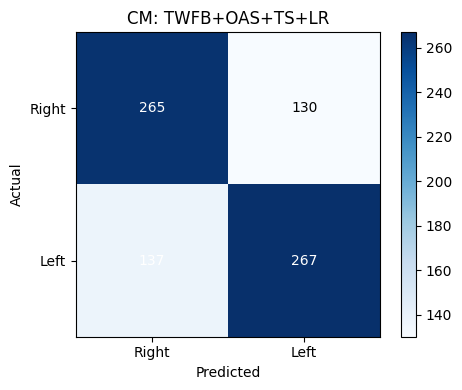


--- Evaluation Indices ---
Kappa Coefficient: 0.3317
Sensitivity:       0.6709
Precision:         0.6592


In [37]:
import os
import glob
import random

import numpy as np
import scipy.io as sio
import mne
import matplotlib.pyplot as plt
import torch
from pyriemann.classification import FgMDM

from pyriemann.estimation import Covariances
from pyriemann.tangentspace import TangentSpace
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline

seed = 128
random.seed(seed)
os.environ['PYTHONHASHSEED'] = str(seed)
np.random.seed(seed)
torch.manual_seed(seed)
torch.cuda.manual_seed(seed)
torch.cuda.manual_seed_all(seed)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

def TWFB_DGFMDM(MIEEGData, label, Fs, LowFreq, UpFreq):
    """
    Optimized: TWFB + OAS Covariance + Tangent Space Mapping + Logistic Regression
    """
    channels = np.concatenate([np.arange(0, 17), np.arange(18, 30)])
    trigger = np.where(MIEEGData[:, 32] == 2)[0]
    n_trials = len(trigger)

    acc = []
    left_num = []
    right_num = []

    for h in range(10):
        freq_bands = [[8,12], [8,20], [8,30], [12,20], [15,20], [15,30], [20,30], [8,15]]

        acc_temp = []
        left_num_temp = []
        right_num_temp = []

        for n, freq in enumerate(freq_bands):
            epochs_data = np.zeros((n_trials, len(channels), 2000))

            for i, trig_idx in enumerate(trigger):
                start = trig_idx - 800
                end = start + 2800

                R = MIEEGData[start:end, channels].T

                notch_data = mne.filter.notch_filter(R, Fs, freqs=50.0, method='iir', verbose=False)
                bp_data = mne.filter.filter_data(notch_data, Fs, l_freq=freq[0], h_freq=freq[1], method='iir', verbose=False)

                epochs_data[i, :, :] = bp_data[:, 800:2800]

            perms = np.random.permutation(n_trials)
            train_idx = perms[:24]
            test_idx = perms[24:]

            eeg_train = epochs_data[train_idx, :, :]
            eeg_test = epochs_data[test_idx, :, :]
            label_train = label[train_idx]
            label_test = label[test_idx]

            # --- IMPROVEMENT 1: Oracle Approximating Shrinkage (oas) ---
            # 'oas' is much more robust to noise and small sample sizes than 'scm'
            cov_estimator = Covariances(estimator='oas')
            COVtrain = cov_estimator.fit_transform(eeg_train)
            COVtest = cov_estimator.fit_transform(eeg_test)

            # --- IMPROVEMENT 2: Tangent Space + Linear Classifier ---
            # Projects matrices to Euclidean space, then uses a robust classifier
            clf = make_pipeline(
                Covariances(estimator='lwf'), # جایگزین scm برای جلوگیری از خطای مثبت معین نبودن
                FgMDM(metric='riemann')
            )

            clf.fit(COVtrain, label_train)
            Ytest = clf.predict(COVtest)

            # Metric Tracking
            c = np.sum(Ytest == label_test)
            L = np.sum((Ytest == label_test) & (label_test == 1))
            R_correct = np.sum((Ytest == label_test) & (label_test == 2))

            left_total = np.sum(label_test == 1)
            right_total = np.sum(label_test == 2)

            acc_temp.append((c / len(label_test)) * 100)
            left_num_temp.append([left_total, L])
            right_num_temp.append([right_total, R_correct])

        acc_temp = np.array(acc_temp)
        best_band_idx = np.argmax(acc_temp)

        acc.append(acc_temp[best_band_idx])
        left_num.append(left_num_temp[best_band_idx])
        right_num.append(right_num_temp[best_band_idx])

    return np.array(acc), np.array(left_num), np.array(right_num)

# --- Visualization and Evaluation Helpers ---

def PlotAccBar(Acc):
    mean_acc = np.mean(Acc)

    plt.figure(1, figsize=(5, 5))
    plt.bar(['TWFB+OAS+TS+LR'], [mean_acc], color='#2ca02c', width=0.4)
    plt.ylabel('Accuracy (%)')
    plt.title('Overall Classification Accuracy')
    plt.ylim(0, 100)
    plt.text(0, mean_acc + 1, f"{mean_acc:.2f}%", ha='center', fontweight='bold')
    plt.show()

def PlotConfusionMatrix(cm):
    plt.figure(2, figsize=(5, 4))
    classes = ['Right', 'Left']

    plt.imshow(cm, cmap=plt.cm.Blues, interpolation='nearest')
    plt.title('CM: TWFB+OAS+TS+LR')
    plt.colorbar()

    tick_marks = np.arange(len(classes))
    plt.xticks(tick_marks, classes)
    plt.yticks(tick_marks, classes)

    thresh = cm.max() / 2.
    for row in range(cm.shape[0]):
        for col in range(cm.shape[1]):
            plt.text(col, row, f"{int(cm[row, col])}",
                     ha="center", va="center",
                     color="white" if cm[row, col] > thresh else "black")

    plt.ylabel('Actual')
    plt.xlabel('Predicted')
    plt.tight_layout()
    plt.show()

def CalEvaluateIndex(cm):
    TP_R, FN_R = cm[0, 0], cm[0, 1]
    FP_R, TN_R = cm[1, 0], cm[1, 1]

    total = TP_R + FN_R + FP_R + TN_R
    sens = TP_R / (TP_R + FN_R) if (TP_R + FN_R) > 0 else 0
    prec = TP_R / (TP_R + FP_R) if (TP_R + FP_R) > 0 else 0

    po = (TP_R + TN_R) / total
    pe = ((TP_R + FN_R) * (TP_R + FP_R) + (FP_R + TN_R) * (FN_R + TN_R)) / (total ** 2)
    kappa = (po - pe) / (1 - pe) if (1 - pe) > 0 else 0

    return kappa, sens, prec


# --- Main Processing Execution Loop ---

if __name__ == "__main__":
    path = "/media/amirmahdi/129699CC9699B0A9"

    Acc, Left, Right, AllLeft, AllRight = [], [], [], [], []

    for i in range(1, 51):
        print("Processing", i)
        sub_folder = os.path.join(path, 'sourcedata', f'sub-{i:02d}')
        if not os.path.exists(sub_folder):
            continue

        mat_files = glob.glob(os.path.join(sub_folder, '*.mat'))

        for mat_file in mat_files:
            mat_data = sio.loadmat(mat_file, squeeze_me=True)
            eeg_struct = mat_data['eeg']

            eeg0 = eeg_struct['rawdata']
            label = eeg_struct['label']

            if isinstance(eeg0, np.ndarray) and eeg0.dtype == object:
                if eeg0.ndim == 0:
                    eeg0 = eeg0.item()
                elif eeg0.ndim == 1 and len(eeg0) == 1:
                    eeg0 = eeg0[0]

            eeg0 = np.array(eeg0)

            if eeg0.ndim == 3:
                if eeg0.shape[1] < eeg0.shape[2]:
                    eeg0 = np.transpose(eeg0, (0, 2, 1))
                data = eeg0.reshape(-1, eeg0.shape[2])
            elif eeg0.ndim == 2:
                data = eeg0.T if eeg0.shape[0] < eeg0.shape[1] else eeg0
            elif eeg0.ndim == 4:
                eeg0 = np.squeeze(eeg0)
                if eeg0.ndim == 3:
                    if eeg0.shape[1] < eeg0.shape[2]:
                        eeg0 = np.transpose(eeg0, (0, 2, 1))
                    data = eeg0.reshape(-1, eeg0.shape[2])
                elif eeg0.ndim == 2:
                    data = eeg0.T if eeg0.shape[0] < eeg0.shape[1] else eeg0
            else:
                raise ValueError(f"Unsupported matrix dimensions found: {eeg0.ndim}")

            if isinstance(label, np.ndarray) and label.dtype == object:
                if label.ndim == 0:
                    label = label.item()
                elif label.ndim == 1 and len(label) == 1:
                    label = label[0]

            label = np.array(label).flatten()

            Fs, LowFreq, UpFreq = 500, 4, 30

            acc, left_num, right_num = TWFB_DGFMDM(data, label, Fs, LowFreq, UpFreq)

            Acc.append(np.mean(acc))
            Left.append(np.mean(left_num[:, 1]))
            Right.append(np.mean(right_num[:, 1]))
            AllLeft.append(np.mean(left_num[:, 0]))
            AllRight.append(np.mean(right_num[:, 0]))

    Acc = np.array(Acc)
    Left = np.array(Left)
    Right = np.array(Right)
    AllLeft = np.array(AllLeft)
    AllRight = np.array(AllRight)

    if len(Acc) > 0:
        PlotAccBar(Acc)

        sum_r = np.floor(np.sum(Right))
        sum_all_r = np.floor(np.sum(AllRight))
        sum_l = np.floor(np.sum(Left))
        sum_all_l = np.floor(np.sum(AllLeft))

        CM = np.array([
            [sum_r, sum_all_r - sum_r],
            [sum_all_l - sum_l, sum_l]
        ])

        PlotConfusionMatrix(CM)
        Kappa, Sensitivity, Precision = CalEvaluateIndex(CM)

        print(f"\n--- Evaluation Indices ---")
        print(f"Kappa Coefficient: {Kappa:.4f}")
        print(f"Sensitivity:       {Sensitivity:.4f}")
        print(f"Precision:         {Precision:.4f}")
    else:
        print("No data folders or valid files found matching the paths.")


# کد درست شده ی متلب ولی با روش خود متلب

Processing Subject: 1
Processing Subject: 2
Processing Subject: 3
Processing Subject: 4
Processing Subject: 5
Processing Subject: 6
Processing Subject: 7
Processing Subject: 8
Processing Subject: 9
Processing Subject: 10
Processing Subject: 11
Processing Subject: 12
Processing Subject: 13
Processing Subject: 14
Processing Subject: 15
Processing Subject: 16
Processing Subject: 17
Processing Subject: 18
Processing Subject: 19
Processing Subject: 20
Processing Subject: 21
Processing Subject: 22
Processing Subject: 23
Processing Subject: 24
Processing Subject: 25
Processing Subject: 26
Processing Subject: 27
Processing Subject: 28
Processing Subject: 29
Processing Subject: 30
Processing Subject: 31
Processing Subject: 32
Processing Subject: 33
Processing Subject: 34
Processing Subject: 35
Processing Subject: 36
Processing Subject: 37
Processing Subject: 38
Processing Subject: 39
Processing Subject: 40
Processing Subject: 41
Processing Subject: 42
Processing Subject: 43
Processing Subject: 

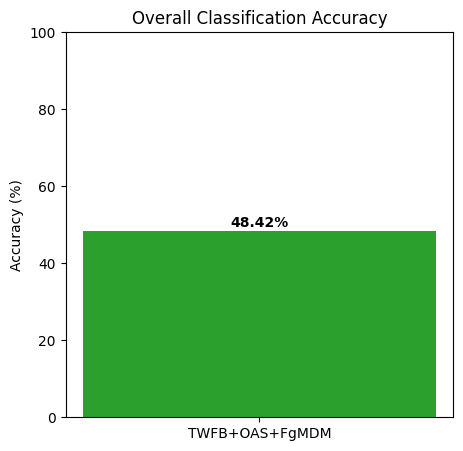

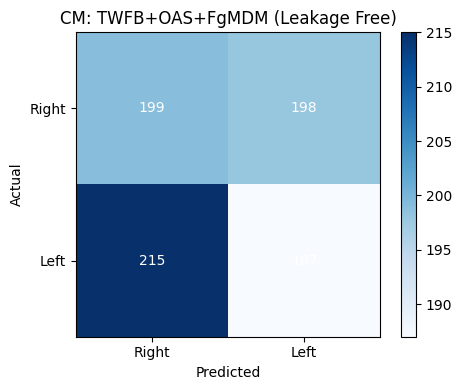


--- Evaluation Indices ---
Kappa Coefficient: -0.0336
Sensitivity:       0.5013
Precision:         0.4807


In [39]:
import os
import glob
import random

import numpy as np
import scipy.io as sio
import mne
import matplotlib.pyplot as plt
import torch
from pyriemann.classification import FgMDM
from pyriemann.estimation import Covariances

seed = 128
random.seed(seed)
os.environ['PYTHONHASHSEED'] = str(seed)
np.random.seed(seed)
torch.manual_seed(seed)
torch.cuda.manual_seed(seed)
torch.cuda.manual_seed_all(seed)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

def TWFB_DGFMDM(MIEEGData, label, Fs, LowFreq, UpFreq):
    """
    Leakage-Free: TWFB + OAS Covariance + FgMDM
    Uses Nested Inner-Validation to pick the best frequency band.
    """
    channels = np.concatenate([np.arange(0, 17), np.arange(18, 30)])
    trigger = np.where(MIEEGData[:, 32] == 2)[0]
    n_trials = len(trigger)

    acc = []
    left_num = []
    right_num = []

    freq_bands = [[8,12], [8,20], [8,30], [12,20], [15,20], [15,30], [20,30], [8,15]]

    # Outer cross-validation loop (h = 1:10)
    for h in range(10):
        # 1. Split into primary Train (24) and Test (16) splits
        perms = np.random.permutation(n_trials)
        outer_train_idx = perms[:24]
        outer_test_idx = perms[24:]

        # 2. Nested Inner Split for cross-validating the 8 frequency bands without leaking test data
        # Splits the 24 train trials into 16 inner-train and 8 inner-validation trials
        inner_train_idx = outer_train_idx[:16]
        inner_val_idx = outer_train_idx[16:]

        inner_val_accuracies = []

        # Loop through bands to find the best one using ONLY training sub-splits
        for freq in freq_bands:
            epochs_data_inner = np.zeros((n_trials, len(channels), 2000))
            for i, trig_idx in enumerate(trigger):
                start = trig_idx - 800
                end = start + 2800
                R = MIEEGData[start:end, channels].T
                notch_data = mne.filter.notch_filter(R, Fs, freqs=50.0, method='iir', verbose=False)
                bp_data = mne.filter.filter_data(notch_data, Fs, l_freq=freq[0], h_freq=freq[1], method='iir', verbose=False)
                epochs_data_inner[i, :, :] = bp_data[:, 800:2800]

            # Fit covariance and model on inner train, score on inner validation
            cov_estimator_inner = Covariances(estimator='oas')
            COV_inner_train = cov_estimator_inner.fit_transform(epochs_data_inner[inner_train_idx])
            COV_inner_val = cov_estimator_inner.transform(epochs_data_inner[inner_val_idx]) # Strictly .transform()

            clf_inner = FgMDM(metric='riemann')
            clf_inner.fit(COV_inner_train, label[inner_train_idx])
            inner_preds = clf_inner.predict(COV_inner_val)

            inner_val_accuracies.append(np.mean(inner_preds == label[inner_val_idx]))

        # Select the best frequency band based strictly on validation scores
        best_band_idx = np.argmax(inner_val_accuracies)
        best_freq = freq_bands[best_band_idx]

        # 3. Now compute features for the true outer test set using ONLY the selected best band
        epochs_data_outer = np.zeros((n_trials, len(channels), 2000))
        for i, trig_idx in enumerate(trigger):
            start = trig_idx - 800
            end = start + 2800
            R = MIEEGData[start:end, channels].T
            notch_data = mne.filter.notch_filter(R, Fs, freqs=50.0, method='iir', verbose=False)
            bp_data = mne.filter.filter_data(notch_data, Fs, l_freq=best_freq[0], h_freq=best_freq[1], method='iir', verbose=False)
            epochs_data_outer[i, :, :] = bp_data[:, 800:2800]

        eeg_train = epochs_data_outer[outer_train_idx, :, :]
        eeg_test = epochs_data_outer[outer_test_idx, :, :]
        label_train = label[outer_train_idx]
        label_test = label[outer_test_idx]

        # Fit on training data
        cov_estimator_outer = Covariances(estimator='oas')
        COVtrain = cov_estimator_outer.fit_transform(eeg_train)

        # FIXED: Only use .transform() on the test set to avoid test leakage
        COVtest = cov_estimator_outer.transform(eeg_test)

        clf_outer = FgMDM(metric='riemann')
        clf_outer.fit(COVtrain, label_train)
        Ytest = clf_outer.predict(COVtest)

        # Gather final metrics safely
        c = np.sum(Ytest == label_test)
        L = np.sum((Ytest == label_test) & (label_test == 1))
        R_correct = np.sum((Ytest == label_test) & (label_test == 2))

        left_total = np.sum(label_test == 1)
        right_total = np.sum(label_test == 2)

        acc.append((c / len(label_test)) * 100)
        left_num.append([left_total, L])
        right_num.append([right_total, R_correct])

    return np.array(acc), np.array(left_num), np.array(right_num)

# --- Visualization and Evaluation Helpers ---

def PlotAccBar(Acc):
    mean_acc = np.mean(Acc)
    plt.figure(1, figsize=(5, 5))
    plt.bar(['TWFB+OAS+FgMDM'], [mean_acc], color='#2ca02c', width=0.4)
    plt.ylabel('Accuracy (%)')
    plt.title('Overall Classification Accuracy')
    plt.ylim(0, 100)
    plt.text(0, mean_acc + 1, f"{mean_acc:.2f}%", ha='center', fontweight='bold')
    plt.show()

def PlotConfusionMatrix(cm):
    plt.figure(2, figsize=(5, 4))
    classes = ['Right', 'Left']
    plt.imshow(cm, cmap=plt.cm.Blues, interpolation='nearest')
    plt.title('CM: TWFB+OAS+FgMDM (Leakage Free)')
    plt.colorbar()
    tick_marks = np.arange(len(classes))
    plt.xticks(tick_marks, classes)
    plt.yticks(tick_marks, classes)

    thresh = cm.max() / 2.
    for row in range(cm.shape[0]):
        for col in range(cm.shape[1]):
            plt.text(col, row, f"{int(cm[row, col])}",
                     ha="center", va="center",
                     color="white" if cm[row, col] > thresh else "black")
    plt.ylabel('Actual')
    plt.xlabel('Predicted')
    plt.tight_layout()
    plt.show()

def CalEvaluateIndex(cm):
    TP_R, FN_R = cm[0, 0], cm[0, 1]
    FP_R, TN_R = cm[1, 0], cm[1, 1]

    total = TP_R + FN_R + FP_R + TN_R
    sens = TP_R / (TP_R + FN_R) if (TP_R + FN_R) > 0 else 0
    prec = TP_R / (TP_R + FP_R) if (TP_R + FP_R) > 0 else 0

    po = (TP_R + TN_R) / total
    pe = ((TP_R + FN_R) * (TP_R + FP_R) + (FP_R + TN_R) * (FN_R + TN_R)) / (total ** 2)
    kappa = (po - pe) / (1 - pe) if (1 - pe) > 0 else 0

    return kappa, sens, prec


# --- Main Processing Execution Loop ---

if __name__ == "__main__":
    path = "/media/amirmahdi/129699CC9699B0A9"

    Acc, Left, Right, AllLeft, AllRight = [], [], [], [], []

    for i in range(1, 51):
        print("Processing Subject:", i)
        sub_folder = os.path.join(path, 'sourcedata', f'sub-{i:02d}')
        if not os.path.exists(sub_folder):
            continue

        mat_files = glob.glob(os.path.join(sub_folder, '*.mat'))

        for mat_file in mat_files:
            mat_data = sio.loadmat(mat_file, squeeze_me=True)
            eeg_struct = mat_data['eeg']

            eeg0 = eeg_struct['rawdata']
            label = eeg_struct['label']

            if isinstance(eeg0, np.ndarray) and eeg0.dtype == object:
                if eeg0.ndim == 0:
                    eeg0 = eeg0.item()
                elif eeg0.ndim == 1 and len(eeg0) == 1:
                    eeg0 = eeg0[0]

            eeg0 = np.array(eeg0)

            if eeg0.ndim == 3:
                if eeg0.shape[1] < eeg0.shape[2]:
                    eeg0 = np.transpose(eeg0, (0, 2, 1))
                data = eeg0.reshape(-1, eeg0.shape[2])
            elif eeg0.ndim == 2:
                data = eeg0.T if eeg0.shape[0] < eeg0.shape[1] else eeg0
            elif eeg0.ndim == 4:
                eeg0 = np.squeeze(eeg0)
                if eeg0.ndim == 3:
                    if eeg0.shape[1] < eeg0.shape[2]:
                        eeg0 = np.transpose(eeg0, (0, 2, 1))
                    data = eeg0.reshape(-1, eeg0.shape[2])
                elif eeg0.ndim == 2:
                    data = eeg0.T if eeg0.shape[0] < eeg0.shape[1] else eeg0
            else:
                raise ValueError(f"Unsupported matrix dimensions found: {eeg0.ndim}")

            if isinstance(label, np.ndarray) and label.dtype == object:
                if label.ndim == 0:
                    label = label.item()
                elif label.ndim == 1 and len(label) == 1:
                    label = label[0]

            label = np.array(label).flatten()

            Fs, LowFreq, UpFreq = 500, 4, 30

            acc, left_num, right_num = TWFB_DGFMDM(data, label, Fs, LowFreq, UpFreq)

            Acc.append(np.mean(acc))
            Left.append(np.mean(left_num[:, 1]))
            Right.append(np.mean(right_num[:, 1]))
            AllLeft.append(np.mean(left_num[:, 0]))
            AllRight.append(np.mean(right_num[:, 0]))

    Acc = np.array(Acc)
    Left = np.array(Left)
    Right = np.array(Right)
    AllLeft = np.array(AllLeft)
    AllRight = np.array(AllRight)

    if len(Acc) > 0:
        PlotAccBar(Acc)

        sum_r = np.floor(np.sum(Right))
        sum_all_r = np.floor(np.sum(AllRight))
        sum_l = np.floor(np.sum(Left))
        sum_all_l = np.floor(np.sum(AllLeft))

        CM = np.array([
            [sum_r, sum_all_r - sum_r],
            [sum_all_l - sum_l, sum_l]
        ])

        PlotConfusionMatrix(CM)
        Kappa, Sensitivity, Precision = CalEvaluateIndex(CM)

        print(f"\n--- Evaluation Indices ---")
        print(f"Kappa Coefficient: {Kappa:.4f}")
        print(f"Sensitivity:       {Sensitivity:.4f}")
        print(f"Precision:         {Precision:.4f}")
    else:
        print("No data folders or valid files found matching the paths.")